Generate H-functions for all three cases

assuming $\eta$ is the het. parameter

# Defs

## Imports

In [16]:
import sys; sys.path.insert(0, '..') # add parent folder path where lib folder is
# user-defined
import couplingPI as cpi
import response as rp

from lib.util import get_phase

from sirv2 import rhs, coupling_social_eta, coupling_physical_eta, coupling_both_eta, coupling_social_gamma, coupling_physical_gamma, coupling_both_gamma

from sirv_lib import load_system, periodic_zero_crossings, plot_crossings, get_pd, get_kw_sim, _redu, tex_num

import lib

import sympy as sym
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

from scipy.signal import find_peaks
import copy
from copy import deepcopy

# for labels
import string
upper_alphabet = string.ascii_uppercase 

from sympy.utilities.lambdify import implemented_function
imp_fn = implemented_function

plt.rcParams.update({
    "text.usetex": True,
    "font.family" : "serif",
    "font.serif"  : "Computer Modern Roman"
})

Matrix = sym.Matrix
CPI = cpi.couplingPI
rsp = rp.Response

In [17]:
print(plt.rcParams['text.usetex'], plt.rcParams['font.family'], plt.rcParams['font.serif'][:1])

True ['serif'] ['Computer Modern Roman']


## RHS coupled

In [2]:
def _full(t,y,systems,hds_dict,option='val'):
    """Full right-hand side. Note that the `coupling` functions contain heterogeneity too."""

    system1,system2 = systems
    pd1 = system1.pardict;pd2 = system2.pardict
    #hd1 = hds[0];hd2 = hds[1] # het. params
    y1 = y[:len(system1.var_names)];y2 = y[len(system1.var_names):]

    c1 = system1.coupling(y,pd1,hds_dict,option,0,version=a.version)
    c2 = system2.coupling(list(y2)+list(y1),pd2,hds_dict,option,1,version=a.version)

    out1 = (system1.rhs(t,y1,pd1,option,0) + c1)
    out2 = (system2.rhs(t,y2,pd2,option,1) + c2)
    return np.array(list(out1)+list(out2))

## kwargs

### sim

In [3]:
# simulation keyword arguments
kw_sim = get_kw_sim()

### model parameters

see `get_pd` in `sirv_lib.py` 

# Response Functions

### get init

In [4]:
pardict = get_pd()
print(pardict)
init0 = [0.17603663,
  0.829848,
  0.99917684]
t = np.arange(0,1000,.01)
out = solve_ivp(rhs,[t[0],t[-1]],init0,t_eval=t,args=(pardict,),**kw_sim)

{'alpha': 0.01, 'beta': 0.5, 'gamma': 0.14285714285714285, 'eta': 0.14285714285714285, 'mu': 0.01, 'kappa': 300, 'rho': 0.01, 'psi': 0.5, 'zeta': 1, 'om': 1, 'om_fix': 1, 'aa': 0}


In [5]:
idxs = find_peaks(out.y[0])[0]
per = np.diff(t[idxs])[-1]

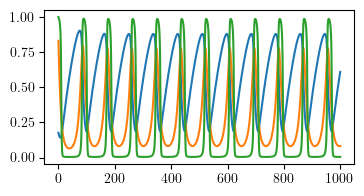

In [6]:
fig,axs = plt.subplots(figsize=(4,2))
axs.plot(out.t,out.y[0])
axs.plot(out.t,out.y[1])
axs.plot(out.t,out.y[2])
init = out.y.T[-1,:]
init = np.append(init,per)

# Coupling (social only)

In [7]:
# 387 approximate pitchfork 
kappas_social_eta = np.round(np.arange(380,397,0.4),3)
as1_social_eta = []
for kap in kappas_social_eta:
    print(kap)
    try:
        system = load_system(kap,type1='social', par='eta', load_data_only=True)
    except AttributeError:
        system = load_system(kap,type1='social', par='eta', load_data_only=False)
    as1_social_eta.append(system)

380.0
380.4
380.8
381.2
381.6
382.0
382.4
382.8
383.2
383.6
384.0
384.4
384.8
385.2
385.6
386.0
386.4
386.8
387.2
387.6
388.0
388.4
388.8
389.2
389.6
390.0
390.4
390.8
391.2
391.6
392.0
392.4
392.8
393.2
393.6
394.0
394.4
394.8
395.2
395.6
396.0
396.4
396.8


## plots combined deltas and aa

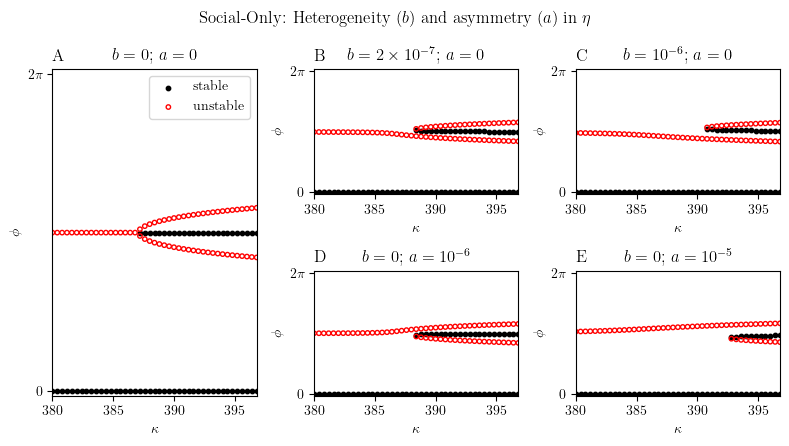

In [32]:
fig, axd = plt.subplot_mosaic([['A', 'B', 'C'],
                               ['A', 'D', 'E']],
                              figsize=(8, 4.5))

syss = as1_social_eta
kaps = kappas_social_eta

kwargs_plots = dict(kappas_in=kaps, systems=syss, M=1000, eps=.05)

plot_crossings(**kwargs_plots, delta=0,     axs=axd['A'], legend=True, label='A')
plot_crossings(**kwargs_plots, delta=2e-7, axs=axd['B'], label='B')
plot_crossings(**kwargs_plots, delta=1e-6, axs=axd['C'], label='C')

plot_crossings(**kwargs_plots, delta=0, aa=1e-6,  axs=axd['D'], label='D')
plot_crossings(**kwargs_plots, delta=0, aa=1e-5, axs=axd['E'], label='E')

plt.suptitle(r'Social-Only: Heterogeneity ($b$) and asymmetry ($a$) in $\eta$')
plt.tight_layout()
plt.savefig('f_social_kappa_eta_aa_b.pdf')

In [9]:
print(axs[0,0]._left_title.get_usetex())

True


# Coupling (physical only)

In [11]:
# 387 approximate pitchfork 
kappas_physical_eta = np.round(np.arange(300,500,20),3)
as1_physical_eta = []
for kap in kappas_physical_eta:
    print(kap)
    try:
        system = load_system(kap, type1='physical', par='eta', load_data_only=True)
    except AttributeError:
        system = load_system(kap,type1='physical', par='eta', load_data_only=False)
    as1_physical_eta.append(system)

300
320
340
360
380
400
420
440
460
480


## plots combined deltas and aa

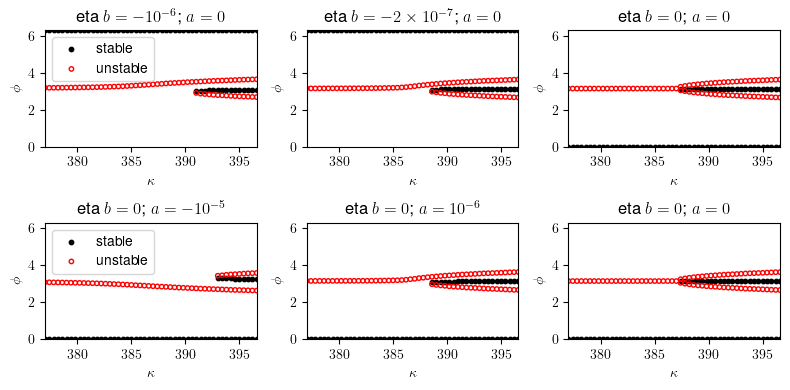

In [15]:
fig,axs = plt.subplots(2,3,figsize=(8,4))

syss = as1_physical_eta
kaps = kappas_physical_eta

axs[0,0] = plot_crossings(eps=.05, delta=-1e-6, kappas_in=kaps, systems=syss, type1='eta',axs=axs[0,0],legend=True)
axs[0,1] = plot_crossings(eps=.05, delta=-2e-7, kappas_in=kaps, systems=syss, type1='eta',axs=axs[0,1])
axs[0,2] = plot_crossings(eps=.05, delta=0, kappas_in=kaps, systems=syss, type1='eta',axs=axs[0,2])

axs[1,0] = plot_crossings(eps=.05, delta=0, aa=-1e-5, kappas_in=kaps, systems=syss, type1='eta',axs=axs[1,0],legend=True)
axs[1,1] = plot_crossings(eps=.05, delta=0, aa=1e-6, kappas_in=kaps, systems=syss, type1='eta',axs=axs[1,1])
axs[1,2] = plot_crossings(eps=.05, delta=0, aa=0, kappas_in=kaps, systems=syss, type1='eta',axs=axs[1,2])

plt.tight_layout()

# Coupling (social + physical)

In [15]:
# 387 approximate pitchfork 
kappas_both_eta = np.round(np.arange(300,302,.1),3)
as1_both_eta = []
for kap in kappas_both_eta:
    print(kap)
    try:
        system = load_system(kap, type1='both', par='eta', load_data_only=True)
    except AttributeError:
        system = load_system(kap,type1='both', par='eta', load_data_only=False)
    as1_both_eta.append(system)

300.0
300.1
300.2
300.3
300.4
300.5
300.6
300.7
300.8
300.9
301.0
301.1
301.2
301.3
301.4
301.5
301.6
301.7
301.8
301.9


## plots (deltas)

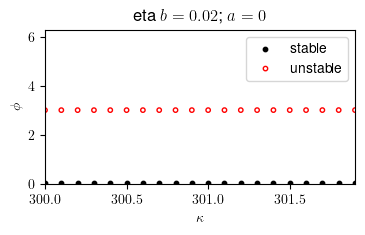

In [16]:
axs = plot_crossings(eps=.05, delta=0.02, kappas_in=kappas_both_eta, systems=as1_both_eta, type1='eta')

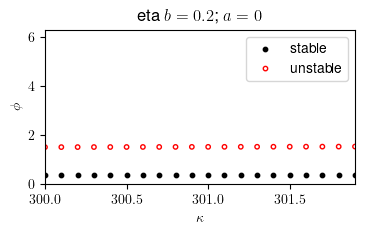

In [17]:
axs = plot_crossings(eps=.05, delta=0.2, kappas_in=kappas_both_eta, systems=as1_both_eta, type1='eta')

## plots (aa)

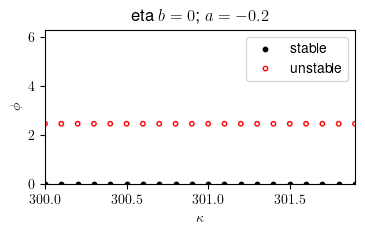

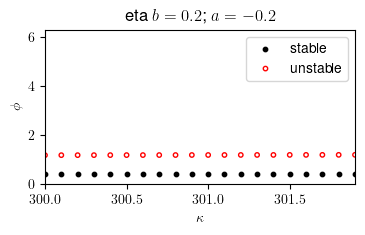

In [18]:
axs = plot_crossings(eps=.05, delta=0., aa=-.2, kappas_in=kappas_both_eta, systems=as1_both_eta, type1='eta')
axs = plot_crossings(eps=.05, delta=0.2, aa=-.2, kappas_in=kappas_both_eta, systems=as1_both_eta, type1='eta')

## plots combined deltas and aa

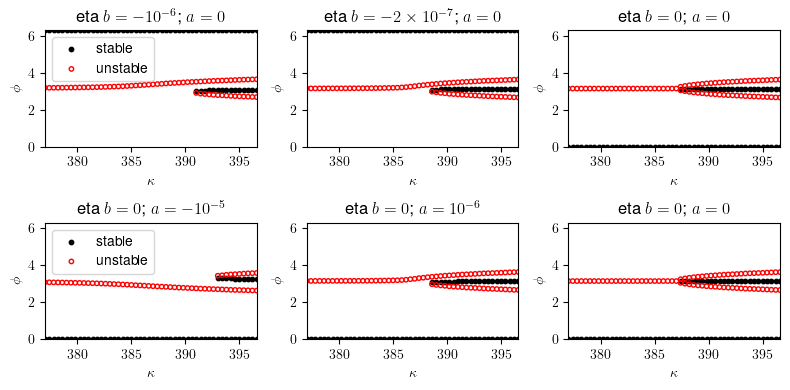

In [15]:
fig,axs = plt.subplots(2,3,figsize=(8,4))

syss = as1_both_eta
kaps = kappas_both_eta

axs[0,0] = plot_crossings(eps=.05, delta=-1e-6, kappas_in=kaps, systems=syss, type1='eta',axs=axs[0,0],legend=True)
axs[0,1] = plot_crossings(eps=.05, delta=-2e-7, kappas_in=kaps, systems=syss, type1='eta',axs=axs[0,1])
axs[0,2] = plot_crossings(eps=.05, delta=0, kappas_in=kaps, systems=syss, type1='eta',axs=axs[0,2])

axs[1,0] = plot_crossings(eps=.05, delta=0, aa=-1e-5, kappas_in=kaps, systems=syss, type1='eta',axs=axs[1,0],legend=True)
axs[1,1] = plot_crossings(eps=.05, delta=0, aa=1e-6, kappas_in=kaps, systems=syss, type1='eta',axs=axs[1,1])
axs[1,2] = plot_crossings(eps=.05, delta=0, aa=0, kappas_in=kaps, systems=syss, type1='eta',axs=axs[1,2])

plt.tight_layout()